# Tutorial 1: Convolutional Neural Networks

## Part 1 — Backpropagation

**How one weight learns: forward propagation, backpropagation, and gradient descent**

One input, one target, one adjustable weight. We will do the calculations first, then name the ideas.

Run the notebook from top to bottom. Use a Python environment with **NumPy, Matplotlib, and ipywidgets** installed (`python -m pip install numpy matplotlib ipywidgets`), and keep `tutorial_1_visuals.py` beside this notebook. Only the learning-rate explorer needs widgets; no data downloads are needed. The short code cells show the learning process; drawing code stays in the helper file.

### 1.1. What are we trying to change?

Given **2**, we want the answer **6**. Try multiplying the input by an adjustable number $w$. Starting with $w=1$ gives $1\times2=2$, so the answer is too small.

| Quantity | Meaning in this example | During training |
|---|---|---|
| Input $x=2$ | The number given to the model | Fixed |
| Target / label $y=6$ | The correct answer | Fixed |
| Weight $w$, initially $w_0=1$ | The adjustable parameter | Changes |
| Prediction $\hat y=wx$ | The model's answer | Changes with $w$ |

The **error** is prediction minus target: $e=\hat y-y$. Squaring it gives a nonnegative score, the **loss**: $L=e^2$. A larger absolute error means a larger loss; a correct prediction gives zero loss.

Training means adjusting **only $w$** to reduce $L=(2w-6)^2$.

### 1.2. What does the current weight predict?

Start at $w=1$ and do three operations:

1. Multiply: $\hat y=1\times2=2$.
2. Subtract: $e=2-6=-4$. The negative error means the prediction is too small.
3. Square: $L=(-4)^2=16$.

In [31]:
x, y = 2.0, 6.0
w = 1.0
prediction = w * x
error = prediction - y
loss = error ** 2
print(f"Prediction = {prediction:g}, error = {error:g}, loss = {loss:g}")

Prediction = 2, error = -4, loss = 16


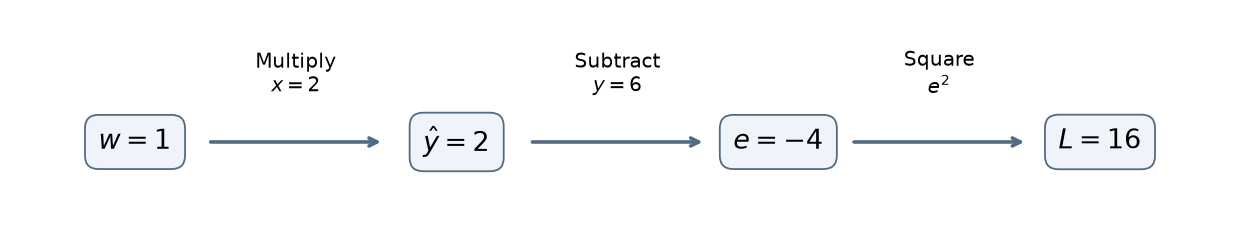

This **computation graph** records how one result feeds into the next operation. The input and target are fixed beside their operations.

Following the graph from the weight to the prediction and loss is **forward propagation** (or **forward**). It evaluates the current weight; it does not change it.

### 1.3. Backward


In [2]:
dL_de = 2 * error
de_dprediction = 1.0
dL_dprediction = dL_de * de_dprediction
dprediction_dw = x
gradient = dL_dprediction * dprediction_dw
print(f"Loss gradients: error {dL_de:g} → prediction {dL_dprediction:g} → weight {gradient:g}")

Loss gradients: error -8 → prediction -8 → weight -16


The weight affects the prediction, which affects the error, which affects the loss. **Multiply the influences along that path**: this is the **chain rule**. For any current weight in this example,

$$\frac{\partial L}{\partial w}=2e\times1\times x
=2(2w-6)\times1\times2=8(w-3).$$

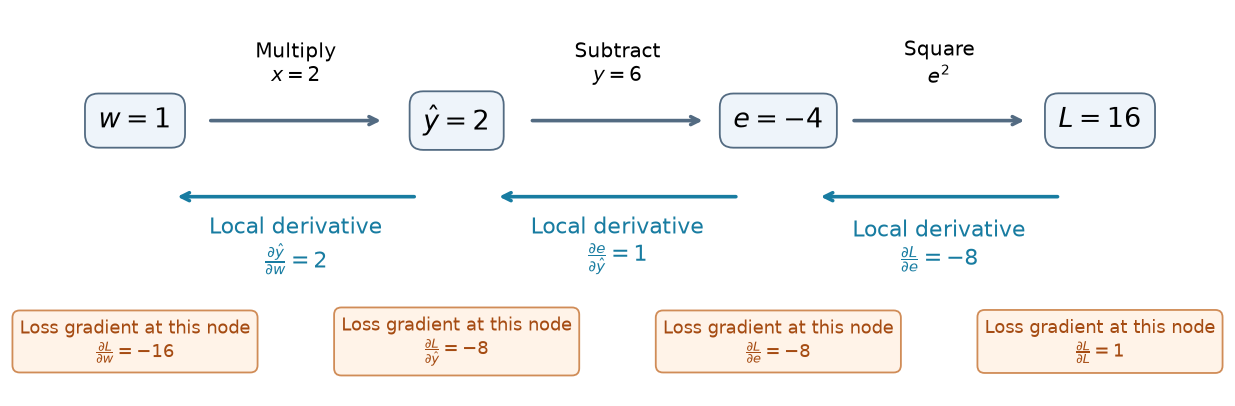

**Blue: local derivatives** describe adjacent nodes. **Orange: loss gradients** combine the influence from a node all the way to the loss. At the last operation these coincide; the loss starts with a gradient of 1 with respect to itself.

Starting at the loss and applying the chain rule backward through the graph to calculate the parameter gradient is **backpropagation**. The weight is still 1; we have only calculated its gradient.

### 1.4. How do we update the weight once?

At $w=1$, the gradient is $-16$: nearby, $\Delta L\approx-16\Delta w$. Increasing the weight a little should therefore reduce the loss.

Use the gradient to choose an update:

$$w_{\mathrm{new}}=w-\eta\times\frac{\partial L}{\partial w}.$$

The **learning rate** $\eta$ controls the step size together with the gradient. Taking $\eta=0.1$ gives $w_{\mathrm{new}}=1-0.1(-16)=2.6$. Recalculate the prediction and loss at this new weight:

In [32]:
eta = 0.1
w_new = w - eta * gradient
prediction_new = w_new * x
error_new = prediction_new - y
loss_new = error_new ** 2
print(f"Weight = {w_new:g}, prediction = {prediction_new:g}, loss = {loss_new:g}")

Weight = 2.6, prediction = 5.2, loss = 0.64


| State | Weight | Prediction | Loss |
| --- | --- | --- | --- |
| Before | 1 | 2 | 16 |
| After | 2.6 | 5.2 | 0.64 |

Subtracting the learning rate times the gradient is **gradient descent**. Here it reduced the loss from 16 to 0.64.

**Backpropagation calculates the gradient; gradient descent updates the parameter.**

### 1.5. What happens when we repeat?

After every update, recalculate the prediction, loss, and gradient **at the new weight**. With $\eta=0.1$, the first five updates give:

| Updates | Current weight | Prediction | Loss | Current gradient |
| --- | --- | --- | --- | --- |
| 0 | 1 | 2 | 16 | -16 |
| 1 | 2.6 | 5.2 | 0.64 | -3.2 |
| 2 | 2.92 | 5.84 | 0.0256 | -0.64 |
| 3 | 2.984 | 5.968 | 0.001024 | -0.128 |
| 4 | 2.9968 | 5.9936 | 4.096e-05 | -0.0256 |
| 5 | 2.99936 | 5.99872 | 1.6384e-06 | -0.00512 |.

Plotting $L(w)=(2w-6)^2=4(w-3)^2$ makes a valley. Its minimum is $(3,0)$, where the prediction is exactly 6.

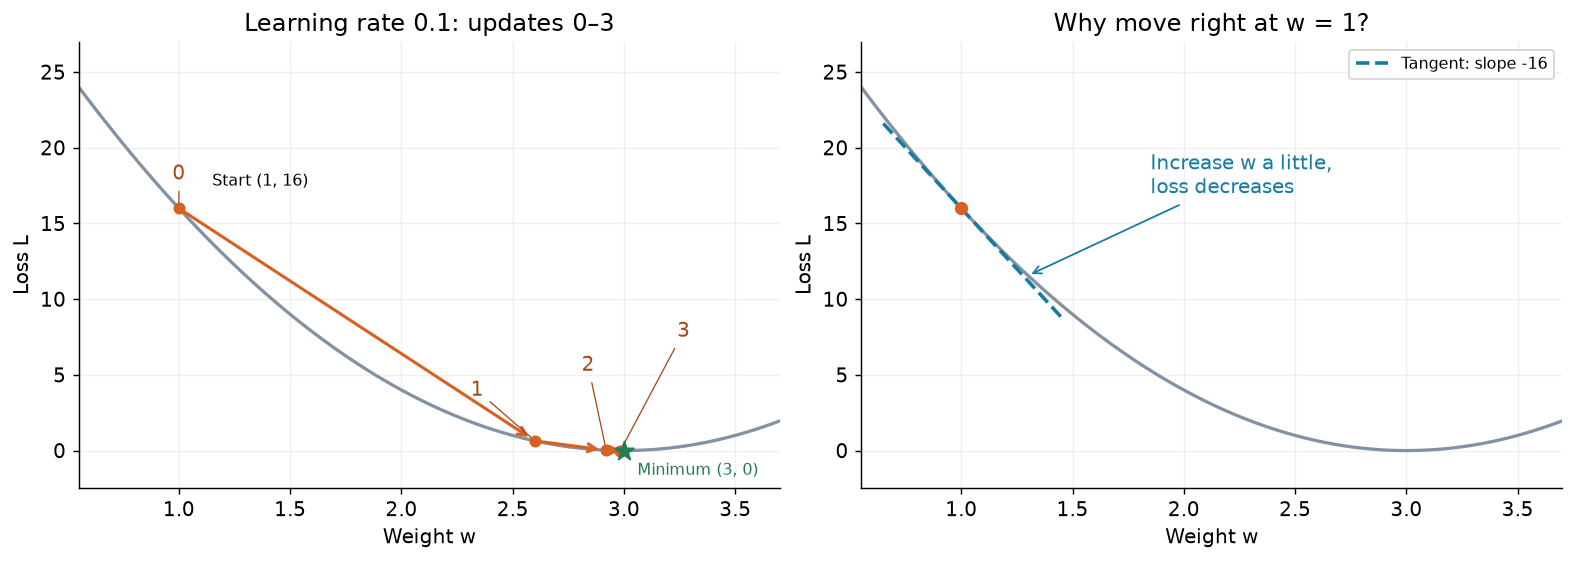


### 1.6. What changes when we change the learning rate?

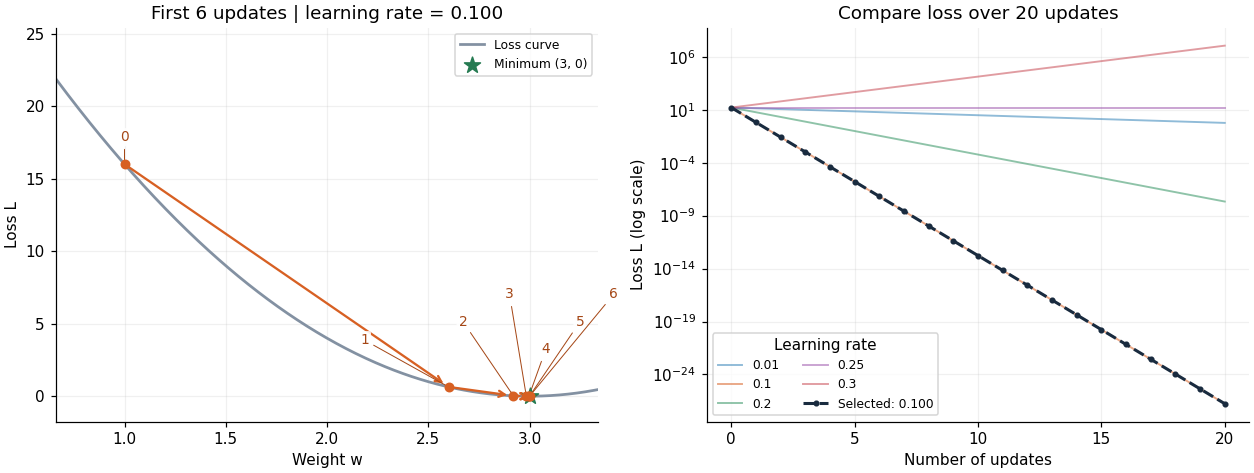

In [22]:
try:
    from tutorial_1_visuals import learning_rate_explorer
except ModuleNotFoundError as exc:
    if exc.name != 'tutorial_1_visuals':
        raise
    from number_classifier.tutorial_1_visuals import learning_rate_explorer

explorer = learning_rate_explorer()
explorer

| Learning rate | What to observe |
| --- | --- |
| 0.01 | Slow convergence |
| 0.1 | Faster convergence |
| 0.2 | Crosses the minimum, but converges |
| 0.25 | Repeats 1 → 5 → 1 → 5; loss stays at 16 |
| 0.3 | Crosses the minimum and diverges |

**Crossing the minimum is not automatically a failure.** What matters is whether later updates get closer.

### 1.7. What is the complete training loop?

```text
Initialize the weight and learning rate.
Repeat: forward → backpropagation → update the weight.
Recalculate the final prediction and loss.
```

Here is the whole process in a small runnable loop. It starts over at $w=1$ and performs the same five updates as the table.

In [5]:
w = 1.0
eta = 0.1

for step in range(5):
    # Forward
    prediction = w * x
    error = prediction - y
    loss = error ** 2

    # Backpropagation: square → subtract → multiply
    dL_de = 2 * error
    de_dprediction = 1.0
    dL_dprediction = dL_de * de_dprediction
    dprediction_dw = x
    gradient = dL_dprediction * dprediction_dw

    # Gradient descent
    w = w - eta * gradient

# Evaluate the final weight; do not reuse the previous loss.
prediction = w * x
error = prediction - y
loss = error ** 2
print(f"After 5 updates: w = {w:.6g}, prediction = {prediction:.6g}, loss = {loss:.6g}")

After 5 updates: w = 2.99936, prediction = 5.99872, loss = 1.6384e-06


This example can achieve **loss = 0** at $w=3$. With $\eta=0.1$, exact arithmetic approaches that weight gradually; a finite run need not reach it exactly, and computers also have floating-point limits. In real tasks, the lowest achievable loss need not be zero.

## Part 2 — From an image to class scores

We now follow an image through **convolution → ReLU → pooling**, repeat that sequence, then **flatten → linear** to obtain class scores. The sections below explain each operation as we reach it.

![A CNN roadmap drawn as feature-map stacks and connections: two convolution/ReLU/pooling stages, flattening, and a linear classifier.](assets/tutorial_1_cnn/cnn_roadmap_wireframe.png)

This is a schematic roadmap, not a drawing to scale. We will add exact shapes as we compute them.

### 2.1 From an image to numbers — a quick review

A grayscale image is a grid of brightness values: **0 is black, 255 is white**. This local MNIST example has label **5**. Its 28 rows, 28 columns, and one brightness value per pixel give **28 × 28 × 1**: height × width × channels.

An RGB image has three **color channels**. The channels produced later by convolution are **feature maps**.

The cells use NumPy, Matplotlib, and **PyTorch** (`torch.nn` provides the layers). No image download is needed.

In [33]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from torch import nn

lesson_dir = Path.cwd()
if not (lesson_dir / "assets/tutorial_1_cnn/digit_5.npy").exists():
    lesson_dir = lesson_dir / "number_classifier"
pixels = np.load(lesson_dir / "assets/tutorial_1_cnn/digit_5.npy")

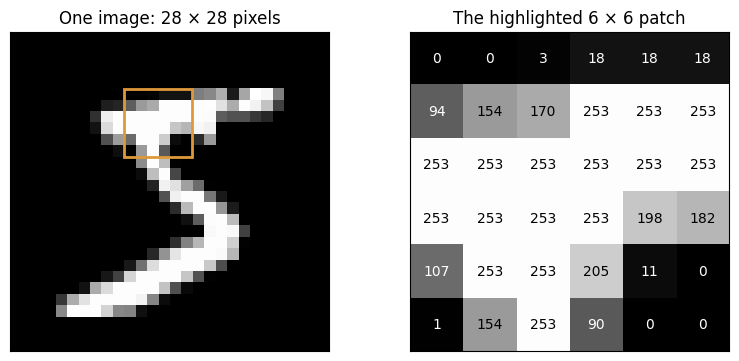

In [34]:
patch = pixels[5:11, 10:16]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout="constrained")
axes[0].imshow(pixels, cmap="gray", vmin=0, vmax=255)
axes[0].add_patch(Rectangle((9.5, 4.5), 6, 6, fill=False, ec="#e09938", lw=2))
axes[0].set_title("One image: 28 × 28 pixels")
axes[1].imshow(patch, cmap="gray", vmin=0, vmax=255)
for (row, col), value in np.ndenumerate(patch):
    axes[1].text(col, row, str(value), ha="center", va="center",
                 color="black" if value > 128 else "white", fontsize=10)
axes[1].set_title("The highlighted 6 × 6 patch")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

### 2.2 How does a convolution produce feature maps?

#### 2.2.1 One moving window, one map of responses

Watch the same **3 × 3 weights** move over a small **5 × 5 input**. At each position, multiply corresponding entries, add the products, then add **one bias**. Write that value into the matching output position.

![Synchronized animation of the input window, fixed weights, elementwise products, and output feature map.](assets/tutorial_1_cnn/sliding_window.gif)

At the first window, the products add to $3+0-2+0+0-1+3+0-2=1$. Adding bias 1 gives **2**. The bias is an adjustable offset. Nine window positions produce a **3 × 3 feature map**: a spatial record of where this filter responds and by how much.

This sliding weighted calculation is a **convolution**. Here, **kernel/filter** means the full set of weights producing **one output channel**. Reusing its weights and bias at every location is **weight sharing**.

**Try the calculation in PyTorch.** A tensor is a multidimensional array. `nn.Conv2d` receives **N × C × H × W**: number of images, channels, height, width. `[None, None]` adds the two size-1 axes for this single grayscale example. The layer stores weights as **output channels × input channels × kernel height × kernel width**.

For example, if you have a input of 3 channel, you need a kernel with size (kernel height × kernel width), for each filter, you need to have 3 different (kernel height × kernel width) slices, and you can have "output channels" numbers of kernels to create "output channels" outputs.

Calling `layer(input)` runs its forward calculation. We use `torch.no_grad()` for this inspection-only pass and for assigning demonstration weights; it skips gradient tracking, not the computation itself.

In [35]:
small_input = torch.tensor([[3., 3., 2., 1., 0.],
                            [0., 0., 1., 3., 1.],
                            [3., 1., 2., 2., 3.],
                            [2., 0., 0., 2., 2.],
                            [2., 0., 0., 0., 1.]])
kernel = torch.tensor([[1., 0., -1.], [1., 0., -1.], [1., 0., -1.]])

small_layer = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3)
with torch.no_grad():
    small_layer.weight[0, 0].copy_(kernel)
    small_layer.bias.fill_(1)
    small_map = small_layer(small_input[None, None])
print("Feature map:\n", small_map[0, 0])
print("N × C × H × W:", tuple(small_map.shape))

Feature map:
 tensor([[ 2., -1.,  2.],
        [ 3., -5., -2.],
        [ 6., -2., -3.]])
N × C × H × W: (1, 1, 3, 3)


**What can a feature map reveal?** Apply three hand-set filters to the same digit: one responds to left–right brightness changes (vertical boundaries), one to up–down changes (horizontal boundaries), and one averages nearby brightness.

This **three-filter illustration** is separate from our four-filter model. `padding=1` adds a border of zeros to retain the image size; Section 2.3 explains that choice. Each filter produces its own map.

In [36]:
vertical = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])
horizontal = vertical.T
average = torch.ones(3, 3) / 9
image_t = torch.from_numpy(pixels).float()[None, None]  # 1 × 1 × 28 × 28

illustration_layer = nn.Conv2d(1, 3, kernel_size=3, padding=1, bias=False)
with torch.no_grad():
    illustration_layer.weight.copy_(torch.stack([vertical, horizontal, average])[:, None])
    example_maps = illustration_layer(image_t)[0]

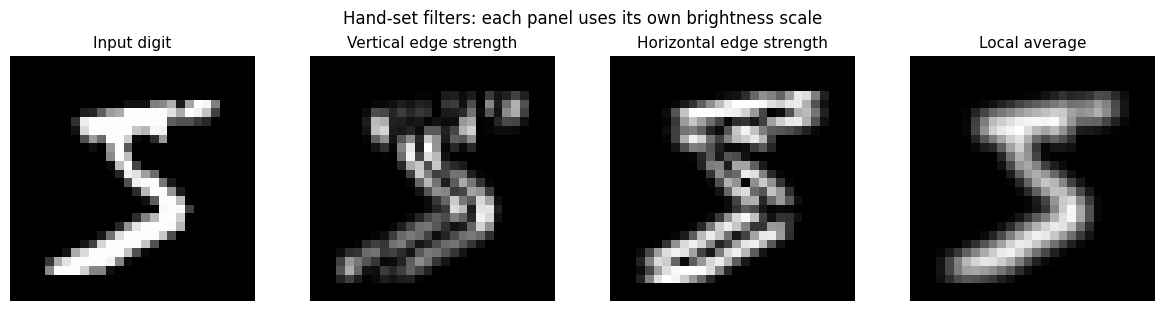

In [37]:
# Absolute values display edge strength; the actual convolution responses are signed.
views = [pixels, example_maps[0].abs().numpy(),
         example_maps[1].abs().numpy(), example_maps[2].numpy()]
titles = ["Input digit", "Vertical edge strength", "Horizontal edge strength", "Local average"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for ax, values, title in zip(axes, views, titles):
    ax.imshow(values, cmap="gray", vmin=0, vmax=values.max())
    ax.set_title(title, fontsize=11)
    ax.axis("off")
fig.suptitle("Hand-set filters: each panel uses its own brightness scale", fontsize=12)
plt.show()

These maps keep different information about the same image.

In a CNN, we normally **learn the filters instead of choosing them**. Backpropagation and parameter updates adjust their weights to reduce the classification loss. The resulting feature maps highlight patterns useful to that task. A filter can be understood as a pattern-sensitive calculation, but its learned role need not have a simple name such as “vertical edge.”

#### 2.2.2 Several input channels, several filters

One filter reads **every input channel** at the same spatial location. It has a **different weight slice for each channel**: multiply each patch by its own slice, sum all those products, and add **one bias**. This produces **one value**, not one value per input channel.

In [11]:
channel_patches = torch.tensor([[[1., 2.], [3., 4.]],
                                [[5., 6.], [7., 8.]]])
channel_weights = torch.tensor([
    [[[1., 0.], [0., -1.]], [[0., 2.], [1., 0.]]],  # filter 0: channels 0, 1
    [[[0., 1.], [1., 0.]], [[1., 0.], [0., 1.]]],   # filter 1: channels 0, 1
])
channel_layer = nn.Conv2d(in_channels=2, out_channels=2, kernel_size=2)
with torch.no_grad():
    channel_layer.weight.copy_(channel_weights)
    channel_layer.bias.copy_(torch.tensor([1., -2.]))
    channel_output = channel_layer(channel_patches[None])
contributions = (channel_weights * channel_patches[None]).sum(dim=(-2, -1))
print("Contributions (rows = filters; columns = input channels):\n", contributions)
print("Separate output channels:", channel_output[0, :, 0, 0].tolist())
print("N × C × H × W:", tuple(channel_output.shape))

Contributions (rows = filters; columns = input channels):
 tensor([[-3., 19.],
        [ 5., 13.]])
Separate output channels: [17.0, 16.0]
N × C × H × W: (1, 2, 1, 1)


**Sum across input channels; keep outputs from different filters separate.** Here the output channels contain 17 and 16; we do **not** add them together. On a larger input, each filter slides to produce a full map, and those maps are stacked as parallel output channels.

Weights differ between channels and between filters. **Spatial positions share weights**: a given filter reuses the same channel-specific slices wherever it moves.

In our complete model, the connection follows exactly this rule:

| Layer | Input channels | Number of filters | Each full filter (H × W × input depth) | Output channels |
|---|---|---|---|---|
| Conv 1 | 1 grayscale channel | 4 | 3 × 3 × 1 | 4 |
| Conv 2 | 4 maps from the first block | 8 | 3 × 3 × 4 | 8 |

ReLU and pooling keep the first block's four channels separate. **Every Conv 2 filter reads all four**, combining their responses; its input depth is four, while the independently chosen filter count is eight. Those eight outputs are parallel maps, not eight sequential layers.

### 2.3 What controls spatial output size?

Compare the highlighted windows below on the same 5 × 5 demonstration input:

![Kernel size, stride, and zero-padding compared using the same five-by-five input.](assets/tutorial_1_cnn/spatial_sizes.png)

- **Kernel size (K)** chooses the spatial window: a 3 × 3 window uses more neighboring positions than a 1 × 1 window. The filter also spans all input channels.
- **Stride (S)** is the distance between window starts. Stride 2 moves two positions at a time, producing fewer output locations.
- **Zero-padding (P)** adds zeros around the border. It allows windows centered near an edge and helps control output size. Padding 1 adds one row or column on each side.

Watch those last two settings in the reference animations. Blue is the input; cyan is the output.

| Padding 1, stride 1 | Padding 0, stride 2 |
|---|---|
| <img src="assets/padding.gif" width="240" alt="A padded five-by-five input produces a five-by-five output."/> | <img src="assets/stride.gif" width="240" alt="Stride two on a five-by-five input produces a two-by-two output."/> |
| 5 × 5 input → 5 × 5 output | 5 × 5 input → 2 × 2 output |

Both animations use 3 × 3 kernels and smaller inputs than our model. 

For our 28-pixel axis, padding 1 creates **30 positions** including the two border zeros. 

the general rule for an ordinary convolution is

$$O=\left\lfloor\frac{I+2P-K}{S}\right\rfloor+1.$$

Apply it separately to height and width: $I$ is the input size, $K$ the window size, $P$ the padding on each side, and $S$ the stride. The floor counts complete windows. For example, $I=6$, $K=3$, $S=2$, $P=0$ gives **2**, even though the division is not exact; the final partial window is simply unused.

These settings determine **height and width**. The **number of filters** independently determines the output channel count. Now run the first convolution of our complete model. The weights below are randomly initialized and **untrained**; their shapes specify four filters, each 3 × 3 × 1.

In [11]:
torch.manual_seed(7)
conv1_layer = nn.Conv2d(in_channels=1, out_channels=4,
                        kernel_size=3, stride=1, padding=1)
with torch.no_grad():
    conv1_t = conv1_layer(image_t)
print("Conv 1 (N, C, H, W):", tuple(image_t.shape), "→", tuple(conv1_t.shape))
print("Weights (out, in, height, width):", tuple(conv1_layer.weight.shape))

Conv 1 (N, C, H, W): (1, 1, 28, 28) → (1, 4, 28, 28)
Weights (out, in, height, width): (4, 1, 3, 3)


### 2.4 Why add ReLU and pooling?

**First, give the model a nonlinear transformation.** ReLU replaces negative values with zero and keeps positive values: $[-2,0,3]\rightarrow[0,0,3]$. It acts on each entry independently, so **28 × 28 × 4 stays 28 × 28 × 4**.

Why does this help? Consider three straight-line functions, applied **in sequence**:

$$f_1(x)=2x+1,\qquad f_2(z)=-z+2,\qquad f_3(z)=0.5z-1.$$

Their composition collapses to another straight line:

$$f_3(f_2(f_1(x)))=0.5[-(2x+1)+2]-1=-x-0.5.$$

Adding more such layers cannot escape this form. Now insert $r(z)=\max(0,z)$ **between** the functions:

$$g(x)=f_3\big(r(f_2(r(f_1(x))))\big).$$

The result can bend: different input ranges follow different slopes. The next plot compares these two cases.

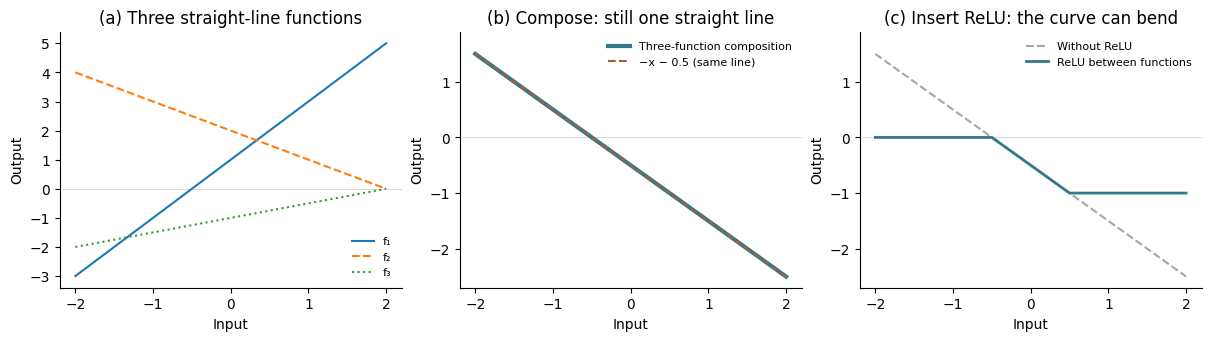

In [15]:
x_demo = torch.linspace(-2, 2, 401)
f1 = lambda z: 2*z + 1
f2 = lambda z: -z + 2
f3 = lambda z: 0.5*z - 1
relu = nn.ReLU()
straight = f3(f2(f1(x_demo)))
nonlinear = f3(relu(f2(relu(f1(x_demo)))))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), layout="constrained")
for f, label, style in zip([f1, f2, f3], ["f₁", "f₂", "f₃"], ["-", "--", ":"]):
    axes[0].plot(x_demo, f(x_demo), style, label=label)
axes[1].plot(x_demo, straight, color="#34788d", lw=3, label="Three-function composition")
axes[1].plot(x_demo, -x_demo - 0.5, "--", color="#a55e36", label="−x − 0.5 (same line)")
axes[2].plot(x_demo, straight, "--", color="0.65", label="Without ReLU")
axes[2].plot(x_demo, nonlinear, color="#34788d", lw=2, label="ReLU between functions")
for ax, title in zip(axes, ["(a) Three straight-line functions", "(b) Compose: still one straight line",
                          "(c) Insert ReLU: the curve can bend"]):
    ax.set(title=title, xlabel="Input", ylabel="Output")
    ax.spines[["top", "right"]].set_visible(False)
    ax.axhline(0, color="0.85", lw=0.7, zorder=0)
    ax.legend(fontsize=8, frameon=False)
axes[1].set_ylim(-2.7, 1.9)
axes[2].set_ylim(-2.7, 1.9)
plt.show()

The two bends show the additional **expressive power**: this function cannot be replaced by one straight line. The same idea applies when convolutions combine many inputs. Negative responses can contain information; ReLU is a chosen nonlinear transformation, not a claim that negative values are useless.

Apply it directly to our first convolution's output:

In [16]:
with torch.no_grad():
    relu1_t = relu(conv1_t)
print("ReLU (N, C, H, W):", tuple(conv1_t.shape), "→", tuple(relu1_t.shape))

ReLU (N, C, H, W): (1, 4, 28, 28) → (1, 4, 28, 28)


**Next, use a coarser spatial grid.** Take the largest value in each **2 × 2 window**, then move two positions to the next window:

![Four two-by-two windows, their selected maxima, and the two-by-two output.](assets/tutorial_1_cnn/max_pool.png)

This is **max pooling**, with window 2 × 2 and stride 2. It operates independently on each channel.

- **Use less memory:**
- **Reduce sensitivity to exact position:**
- **Combine features over a wider area:** each pooled position summarizes a small region. The next convolution can combine edge responses spread across a larger area of the original image, helping represent larger shapes.

This trades away some spatial detail. Channel count stays unchanged: **28 × 28 × 4 → 14 × 14 × 4**. Pooling is one downsampling option; strided convolutions are another.

In [17]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)
pool_example = torch.tensor([[1., 3., 2., 0.], [4., 2., 1., 5.],
                             [0., 1., 7., 2.], [2., 6., 3., 4.]])
print("Small example:\n", pool(pool_example[None, None])[0, 0])
with torch.no_grad():
    pool1_t = pool(relu1_t)
print("First pool (N, C, H, W):", tuple(relu1_t.shape), "→", tuple(pool1_t.shape))

Small example:
 tensor([[4., 5.],
        [6., 7.]])
First pool (N, C, H, W): (1, 4, 28, 28) → (1, 4, 14, 14)


**Complete the second block.** Its eight filters each combine all four incoming channels, as explained in 2.2.2. The same convolution settings preserve 14 × 14; ReLU preserves shape, and pooling reduces it to **7 × 7 × 8**. These model weights are randomly initialized and **untrained**.

In [18]:
conv2_layer = nn.Conv2d(in_channels=4, out_channels=8,
                        kernel_size=3, stride=1, padding=1)
with torch.no_grad():
    conv2_t = conv2_layer(pool1_t)
    relu2_t = relu(conv2_t)
    pool2_t = pool(relu2_t)
print("Conv 2 (N, C, H, W):", tuple(pool1_t.shape), "→", tuple(conv2_t.shape))
print("ReLU → pool:", tuple(relu2_t.shape), "→", tuple(pool2_t.shape))

Conv 2 (N, C, H, W): (1, 4, 14, 14) → (1, 8, 14, 14)
ReLU → pool: (1, 8, 14, 14) → (1, 8, 7, 7)


The following classifier section uses NumPy arrays in **height × width × channels** order. To continue with the exact values just computed, remove the single-image axis and reorder the remaining axes. This changes the representation, not the feature values.

In [19]:
image, conv1, relu1, pool1, conv2, relu2, pool2 = [
    values[0].permute(1, 2, 0).numpy()
    for values in (image_t, conv1_t, relu1_t, pool1_t, conv2_t, relu2_t, pool2_t)
]
rng = np.random.default_rng(7)
# Utilities used by the existing classifier section below.
try:
    import tutorial_1_cnn_helpers as cnn
except ModuleNotFoundError as exc:
    if exc.name != "tutorial_1_cnn_helpers":
        raise
    from number_classifier import tutorial_1_cnn_helpers as cnn

### 2.6 From feature maps to class scores

We have eight 7 × 7 feature maps, but classification needs **one score per digit**. First arrange all their entries into one ordered list:

$$7\times7\times8=392.$$

This is **flattening**. It changes the shape to **392 values**, preserving every value and learning no parameters. The fixed order tells the following layer which feature each position represents.

In [27]:
features = pool2.reshape(-1)
print("Flatten:", pool2.shape, "→", features.shape)

Flatten: (7, 7, 8) → (392,)


Next, a **linear layer** maps the 392 features to **10 class scores (logits)**, one for each digit (0–9).

Each score is a weighted sum plus a bias. In code, `@` computes all ten sums at once. These weights are untrained, so the scores only illustrate the calculation.

Linear: (392,) → (10,)
Predicted digit: 2


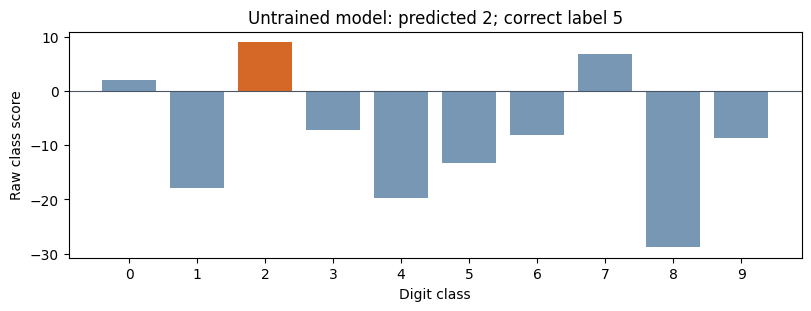

In [28]:
linear_weights = rng.normal(0, 0.03, size=(392, 10))
linear_bias = np.zeros(10)
scores = features @ linear_weights + linear_bias
predicted_digit = int(np.argmax(scores))
print("Linear:", features.shape, "→", scores.shape)
print("Predicted digit:", predicted_digit)
cnn.show_scores(scores, target=5)

The digit with the **highest score** is the prediction. To express these scores as probabilities, we use **softmax**:

$$
p_k = \frac{e^{s_k}}{\sum_{j=0}^{9} e^{s_j}}
$$

Here, $s_k$ is the score for digit $k$, and $p_k$ is its probability. Exponentiation makes each value positive; dividing by their total makes the probabilities sum to 1. The highest score still gives the highest probability.

We use the same **squared error** as in Part 1, now summed over all ten outputs. For this image of digit 5, the target is 1 at position 5 and 0 elsewhere:

$$
y = [0,0,0,0,0,1,0,0,0,0], \qquad L = \sum_{k=0}^{9}(p_k-y_k)^2.
$$

The closer the predicted probabilities are to these targets, the smaller the loss.

In [29]:
# Softmax: subtracting the largest score keeps exponentials stable.
exp_scores = np.exp(scores - scores.max())
probabilities = exp_scores / exp_scores.sum()

target = np.zeros(10)
target[5] = 1.0
error = probabilities - target
loss = np.sum(error ** 2)
print(f"Untrained model's squared-error loss: {loss:.4f}")

Untrained model's squared-error loss: 1.8319


Training follows the same steps as Part 1: **backpropagation** calculates the gradients, and **gradient descent** updates the weights and biases. Here, we update both convolutional layers and the linear layer.

So far, we have only calculated the outputs and loss; and not updated any weights. The table below summarizes each layer's output shape and learnable parameters:

In [30]:
stages = [
    ("Input", image, "—"),
    ("Conv 1", conv1, "Weights + biases"), ("ReLU", relu1, "—"),
    ("MaxPool", pool1, "—"),
    ("Conv 2", conv2, "Weights + biases"), ("ReLU", relu2, "—"),
    ("MaxPool", pool2, "—"), ("Flatten", features, "—"),
    ("Linear", scores, "Weights + biases"),
]
cnn.Table(["Operation", "Actual output shape", "Learnable parameters"],
          [(name, " × ".join(map(str, values.shape)), params) for name, values, params in stages])

Operation,Actual output shape,Learnable parameters
Input,28 × 28 × 1,—
Conv 1,28 × 28 × 4,Weights + biases
ReLU,28 × 28 × 4,—
MaxPool,14 × 14 × 4,—
Conv 2,14 × 14 × 8,Weights + biases
ReLU,14 × 14 × 8,—
MaxPool,7 × 7 × 8,—
Flatten,392,—
Linear,10,Weights + biases


## Part 3 — CNN in PyTorch

Part 2 explained the operations. Here we introduce the core PyTorch command, then connect the commands into one model and a training loop.

We keep the same architecture: two **convolution → ReLU → pooling** blocks, then **FFN layers → 10 scores**. All computations in this section are visible here. The examples reuse the local digit from Part 2; no dataset download or plots are needed.

### 3.1 Prepare the input: tensors, dimensions, and devices

**Requirement:** pass one 28 × 28 grayscale image and its correct digit to a CNN.

PyTorch's convolution layout is **N × C × H × W**. `N` is the number of images processed together, called the **batch size**. It is not a convolution-layer parameter: the same layer can process one image or several.

For class-index labels, use integer type `torch.long` and shape **(N,)**. A label is a digit ID, not a floating-point image value. We use the CPU so the example runs without a GPU.

In [22]:
import torch
from torch import nn

pt_device = torch.device("cpu")
pt_images = torch.from_numpy(pixels).float().unsqueeze(0).unsqueeze(0).to(pt_device)
pt_labels = torch.tensor([5], dtype=torch.long, device=pt_device)
print("Images:", tuple(pt_images.shape), pt_images.dtype, pt_images.device)
print("Labels:", tuple(pt_labels.shape), pt_labels.dtype)

Images: (1, 1, 28, 28) torch.float32 cpu
Labels: (1,) torch.int64


### 3.2 Configure `nn.Conv2d` from a concrete requirement

**Requirement:** receive one grayscale channel, produce four feature maps, use 3 × 3 windows, and preserve 28 × 28 spatial size.

```python
nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3,
          stride=1, padding=1, bias=True)
```

| Argument | Meaning | How to choose it |
|---|---|---|
| `in_channels` | Number of channels in the incoming tensor | Must match its C dimension: 1 for our image, 4 for the next convolution |
| `out_channels` | Number of independent filters | An architecture choice: 4 in our first layer, 8 in the second |
| `kernel_size` | Height and width of each spatial window | `3` means 3 × 3; `(3, 5)` means height 3 and width 5 |
| `bias` | Whether each filter has one learned offset | `True` is the default; `False` removes those offsets |

**Try three requirements on the same image:**

In [23]:
torch.manual_seed(7)
pt_conv_examples = {
    "4 maps, 3 × 3 window, keep size": nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1),
    "4 maps, 5 × 5 window, keep size": nn.Conv2d(1, 4, kernel_size=5, stride=1, padding=2),
    "4 maps, 3 × 3 window, downsample": nn.Conv2d(1, 4, kernel_size=3, stride=2, padding=1),
}
with torch.no_grad():
    for description, layer in pt_conv_examples.items():
        print(description, "→", tuple(layer(pt_images).shape))

4 maps, 3 × 3 window, keep size → (1, 4, 28, 28)
4 maps, 5 × 5 window, keep size → (1, 4, 28, 28)
4 maps, 3 × 3 window, downsample → (1, 4, 14, 14)



`layer.weight` is ordered **(out_channels, in_channels, kernel_height, kernel_width)**; `layer.bias` has one entry per output channel. Thus the second layer's command is `nn.Conv2d(4, 8, 3, padding=1)`, with weights shaped **(8, 4, 3, 3)**. PyTorch initializes these learnable tensors automatically. Reuse the layer object to reuse its weights; constructing another layer creates another set of parameters.

### 3.3 Add `nn.ReLU` and `nn.MaxPool2d`

**Requirement:** apply ReLU after the first convolution, then halve height and width while keeping all four channels.

- `nn.ReLU()` applies `max(0, value)` to each entry. It preserves shape and has no learned parameters.
- `nn.MaxPool2d(kernel_size=2, stride=2)` selects one maximum per 2 × 2 window, moving two positions each time. `kernel_size` sets the region; `stride` sets the movement. Setting them explicitly makes the intended downsampling clear.
- Pooling uses `padding=0` and `ceil_mode=False` by default. With these settings it counts only complete windows, using floor division. For example, a 15 × 15 input becomes 7 × 7 with this 2 × 2, stride-2 pool; an unmatched trailing row or column is not used.

These modules are called just like convolution layers:

In [24]:
pt_conv = pt_conv_examples["4 maps, 3 × 3 window, keep size"]
pt_relu = nn.ReLU()
pt_pool = nn.MaxPool2d(kernel_size=2, stride=2)
with torch.no_grad():
    pt_response = pt_conv(pt_images)
    pt_activated = pt_relu(pt_response)
    pt_pooled = pt_pool(pt_activated)
print("Conv:", tuple(pt_response.shape))
print("ReLU:", tuple(pt_activated.shape))
print("Pool:", tuple(pt_pooled.shape))

Conv: (1, 4, 28, 28)
ReLU: (1, 4, 28, 28)
Pool: (1, 4, 14, 14)


**Build the second block from that output.** The first pool produced **(N, 4, 14, 14)**, so the next convolution needs `in_channels=4`. Choose `out_channels=8` for eight feature maps. A 3 × 3 kernel with stride 1 and padding 1 keeps 14 × 14; ReLU preserves the shape, and a second 2 × 2 pool reduces it to **(N, 8, 7, 7)**.

We can reuse `pt_relu` and `pt_pool`: neither holds learned parameters. The second convolution is a new layer with its own weights.

In [25]:
pt_conv2 = nn.Conv2d(in_channels=4, out_channels=8,
                     kernel_size=3, stride=1, padding=1).to(pt_device)
with torch.no_grad():
    pt_response2 = pt_conv2(pt_pooled)
    pt_activated2 = pt_relu(pt_response2)
    pt_pooled2 = pt_pool(pt_activated2)
print("Conv 2:", tuple(pt_response2.shape))
print("ReLU:", tuple(pt_activated2.shape))
print("Pool 2:", tuple(pt_pooled2.shape))

Conv 2: (1, 8, 14, 14)
ReLU: (1, 8, 14, 14)
Pool 2: (1, 8, 7, 7)


### 3.4 Configure `nn.Flatten` and `nn.Linear`

**Requirement:** turn each image's eight 7 × 7 maps into ten digit scores.

`nn.Flatten(start_dim=1)` merges all axes from axis 1 onward, keeping axis 0—the batch—separate. It turns **(N, 8, 7, 7)** into **(N, 392)** because 8 × 7 × 7 = 392. It has no learned parameters. `torch.flatten(values, start_dim=1)` is the equivalent function form.

Do not use `start_dim=0` here: it would merge different images into one vector. 

`nn.Linear(in_features=392, out_features=10, bias=True)` receives 392 values **per image**, then produces ten learned weighted sums. `in_features` must match the actual flattened size; `out_features` is the number of classes. Its stored weight shape is **(10, 392)** and bias shape is **(10,)**. If earlier spatial settings change, recalculate `in_features`.

Continue with the **actual second-block output** from 3.3. For our single image, the shapes are **(1, 8, 7, 7) → (1, 392) → (1, 10)**. These scores come from randomly initialized, untrained layers.

In [26]:
pt_flatten = nn.Flatten(start_dim=1)
pt_linear = nn.Linear(in_features=8 * 7 * 7, out_features=10)
with torch.no_grad():
    pt_demo_features = pt_flatten(pt_pooled2)
    pt_demo_scores = pt_linear(pt_demo_features)
print("Maps:", tuple(pt_pooled2.shape))
print("Flatten:", tuple(pt_demo_features.shape))
print("Linear:", tuple(pt_demo_scores.shape))

Maps: (1, 8, 7, 7)
Flatten: (1, 392)
Linear: (1, 10)


### 3.5 Put the layers in `nn.Module`

**Requirement:** define one reusable CNN with the architecture from Part 2.

- Subclass `nn.Module` to give the model parameter tracking and methods such as `.to()`, `.train()`, and `.eval()`.
- In `__init__`, call `super().__init__()` first, then create layers as `self` attributes. This registers their parameters. Create learnable layers **once here**, not inside `forward`, where they would be recreated on every call.
- `nn.Sequential(...)` chains modules: each output becomes the next input. It is convenient for our two feature-extraction blocks.
- `forward(self, images)` describes the computation. Call **`model(images)`**, which invokes `forward` through PyTorch's module machinery; do not normally call `model.forward(images)` directly.
- No manual backward method is needed: PyTorch records supported operations during the forward pass and differentiates them when requested.

In [ ]:
class TutorialCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(4, 8, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.flatten = nn.Flatten(start_dim=1)
        self.classifier = nn.Linear(in_features=392, out_features=10)

    def forward(self, images):
        maps = self.features(images)
        features = self.flatten(maps)
        return self.classifier(features)